In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
print("Notebook cwd:", cwd)

project_root = cwd
while not (project_root / "analysis").exists():
    if project_root.parent == project_root:
        raise RuntimeError("Could not find project root containing 'analysis'")
    project_root = project_root.parent

sys.path.insert(0, str(project_root))
print("Added project root to sys.path:", project_root)

import analysis
print("analysis loaded from:", analysis.__file__)


Notebook cwd: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/notebooks
Added project root to sys.path: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator
analysis loaded from: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/__init__.py


In [2]:
from pathlib import Path

from analysis import (
    BatchLoader,
    ExperimentAggregator,
    StatisticalAnalyzer,
    TrajectoryVisualizer,
    HeatmapVisualizer,
    MetricsVisualizer
)

In [3]:
PROJECT_ROOT = project_root
EXPERIMENTS_DIR = PROJECT_ROOT / "experiments"
REPORT_DIR = PROJECT_ROOT / "report"

print("Project root:", PROJECT_ROOT)
print("Experiments dir:", EXPERIMENTS_DIR)
print("Report dir:", REPORT_DIR)

Project root: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator
Experiments dir: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/experiments
Report dir: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report


In [4]:
batch = BatchLoader(EXPERIMENTS_DIR)
experiments = batch.load_all()

print(f"Loaded {len(experiments)} experiments")

experiments[0] if experiments else "No experiments loaded"

✓ Loaded Experiment(run_id=bb3e572f, seed=1768277105, strategies=6, agents=4, parcels=8)
Loaded 1 experiments


Experiment(run_id=bb3e572f, seed=1768277105, strategies=6, agents=4, parcels=8)

In [5]:
agg = ExperimentAggregator(experiments)

df = agg.dataframe
df.head()

,run_id,seed,strategy_name,planner,mission_makespan_steps,total_energy_consumed,total_distance_traveled,tasks_completed,unsafe_failures,messages_sent,...,energy_per_task,distance_per_task,efficiency_ratio,failure_rate,n_drones,n_parcels,comm_reliability,battery_capacity,n_collisions,parcels_delivered
0,bb3e572f,1768277105,naive_decentralized,local,659,53.796,29.0,8,396,0,...,6.724500,3.625,0.539074,49.500,4,8,1.0,100.0,396,8
1,bb3e572f,1768277105,centralized_cc,local,485,38.999,17.0,8,15,0,...,4.874875,2.125,0.435909,1.875,4,8,1.0,100.0,15,8
2,bb3e572f,1768277105,sppdec_control,local,422,52.112,28.0,8,185,0,...,6.514000,3.500,0.537304,23.125,4,8,1.0,100.0,185,8
3,bb3e572f,1768277105,sppdec_baseline_only,local,536,58.548,28.0,8,97,0,...,7.318500,3.500,0.478240,12.125,4,8,1.0,100.0,97,8
4,bb3e572f,1768277105,sppdec_fairness_only,local,498,50.010,26.0,8,147,0,...,6.251250,3.250,0.519896,18.375,4,8,1.0,100.0,147,8


In [6]:
summary = agg.summary()
summary

mission_makespan_steps                \
                                       mean std  min  max   
strategy_name                                               
centralized_cc                        485.0 NaN  485  485   
naive_decentralized                   659.0 NaN  659  659   
sppdec_baseline_only                  536.0 NaN  536  536   
sppdec_combined                       679.0 NaN  679  679   
sppdec_control                        422.0 NaN  422  422   
sppdec_fairness_only                  498.0 NaN  498  498   

                     total_energy_consumed                    \
                                      mean std    min    max   
strategy_name                                                  
centralized_cc                       39.00 NaN  39.00  39.00   
naive_decentralized                  53.80 NaN  53.80  53.80   
sppdec_baseline_only                 58.55 NaN  58.55  58.55   
sppdec_combined                      68.28 NaN  68.28  68.28   
sppdec_control                       52.11 NaN  52.11  52.11   
sppdec_fairness_only                 50.01 NaN  50.01  50.01   

                     total_distance_traveled      ... energy_per_task  \
                                        mean std  ...             cv%   
strategy_name                                     ...                   
centralized_cc                          17.0 NaN  ...             NaN   
naive_decentralized                     29.0 NaN  ...             NaN   
sppdec_baseline_only                    28.0 NaN  ...             NaN   
sppdec_combined                         29.0 NaN  ...             NaN   
sppdec_control                          28.0 NaN  ...             NaN   
sppdec_fairness_only                    26.0 NaN  ...             NaN   

                     distance_per_task efficiency_ratio failure_rate n_drones  \
                                   cv%              cv%          cv%      cv%   
strategy_name                                                                   
centralized_cc                     NaN              NaN          NaN      NaN   
naive_decentralized                NaN              NaN          NaN      NaN   
sppdec_baseline_only               NaN              NaN          NaN      NaN   
sppdec_combined                    NaN              NaN          NaN      NaN   
sppdec_control                     NaN              NaN          NaN      NaN   
sppdec_fairness_only               NaN              NaN          NaN      NaN   

                     n_parcels comm_reliability battery_capacity n_collisions  \
                           cv%              cv%              cv%          cv%   
strategy_name                                                                   
centralized_cc             NaN              NaN              NaN          NaN   
naive_decentralized        NaN              NaN              NaN          NaN   
sppdec_baseline_only       NaN              NaN              NaN          NaN   
sppdec_combined            NaN              NaN              NaN          NaN   
sppdec_control             NaN              NaN              NaN          NaN   
sppdec_fairness_only       NaN              NaN              NaN          NaN   

                     parcels_delivered  
                                   cv%  
strategy_name                           
centralized_cc                     NaN  
naive_decentralized                NaN  
sppdec_baseline_only               NaN  
sppdec_combined                    NaN  
sppdec_control                     NaN  
sppdec_fairness_only               NaN  

[6 rows x 85 columns]

In [7]:
analyzer = StatisticalAnalyzer(agg)

analyzer.pairwise_ttest(
    metric="mission_makespan_steps",
    baseline_strategy="sppdec_combined"
)

/home/iamthevectorian/.local/share/virtualenvs/MultiAgentSimulator-z0UKPZKH/lib/python3.9/site-packages/scipy/stats/_stats_py.py:6951: RuntimeWarning: invalid value encountered in scalar divide
  svar = ((n1 - 1) * v1 + (n2 - 1) * v2) / df


,comparison_strategy,baseline_mean,comparison_mean,difference,pct_difference,t_statistic,p_value,significance,cohens_d,n_baseline,n_comparison
0,naive_decentralized,679.0,659.0,-20.0,-2.9455,NaN,NaN,ns,NaN,1,1
1,centralized_cc,679.0,485.0,-194.0,-28.5714,NaN,NaN,ns,NaN,1,1
2,sppdec_control,679.0,422.0,-257.0,-37.8498,NaN,NaN,ns,NaN,1,1
3,sppdec_baseline_only,679.0,536.0,-143.0,-21.0604,NaN,NaN,ns,NaN,1,1
4,sppdec_fairness_only,679.0,498.0,-181.0,-26.6568,NaN,NaN,ns,NaN,1,1


/home/iamthevectorian/.local/share/virtualenvs/MultiAgentSimulator-z0UKPZKH/lib/python3.9/site-packages/scipy/stats/_stats_py.py:4102: DegenerateDataWarning: all input arrays have length 1.  f_oneway requires that at least one input has length greater than 1.
  if _f_oneway_is_too_small(samples):


Generating statistical report...
✓ Summary statistics
✓ ANOVA results


/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/aggregators.py:264: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/aggregators.py:289: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


✓ Saved boxplot: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report/boxplot_mission_makespan_steps.png


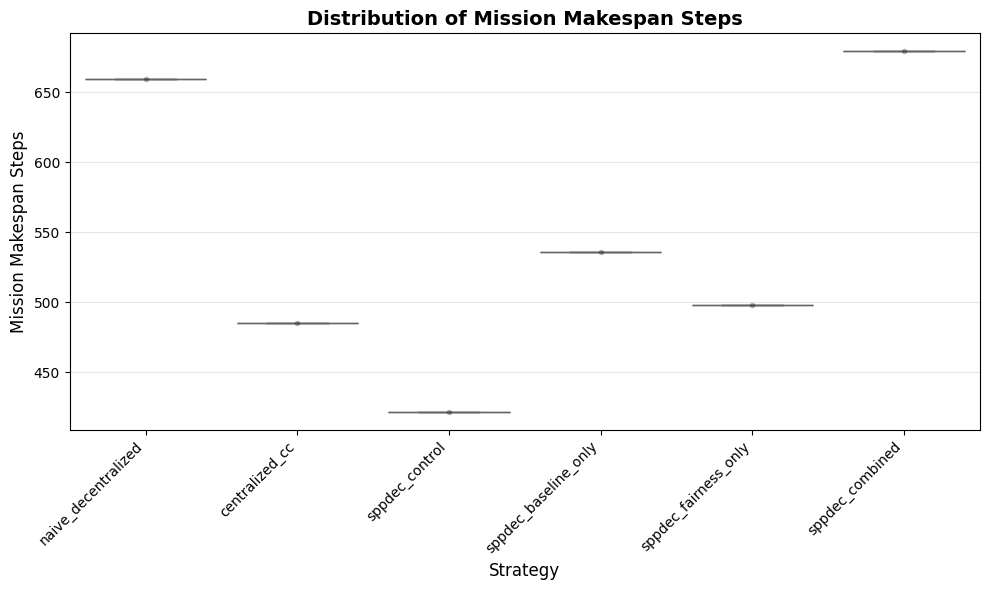

/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/aggregators.py:264: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/aggregators.py:289: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


✓ Saved boxplot: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report/boxplot_total_energy_consumed.png


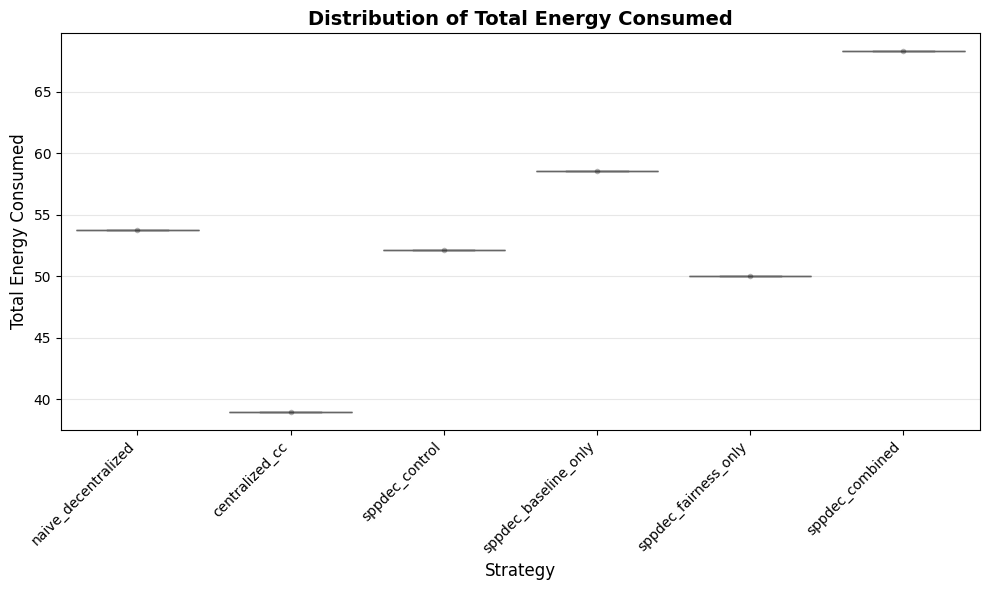

/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/aggregators.py:264: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/aggregators.py:289: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


✓ Saved boxplot: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report/boxplot_total_distance_traveled.png


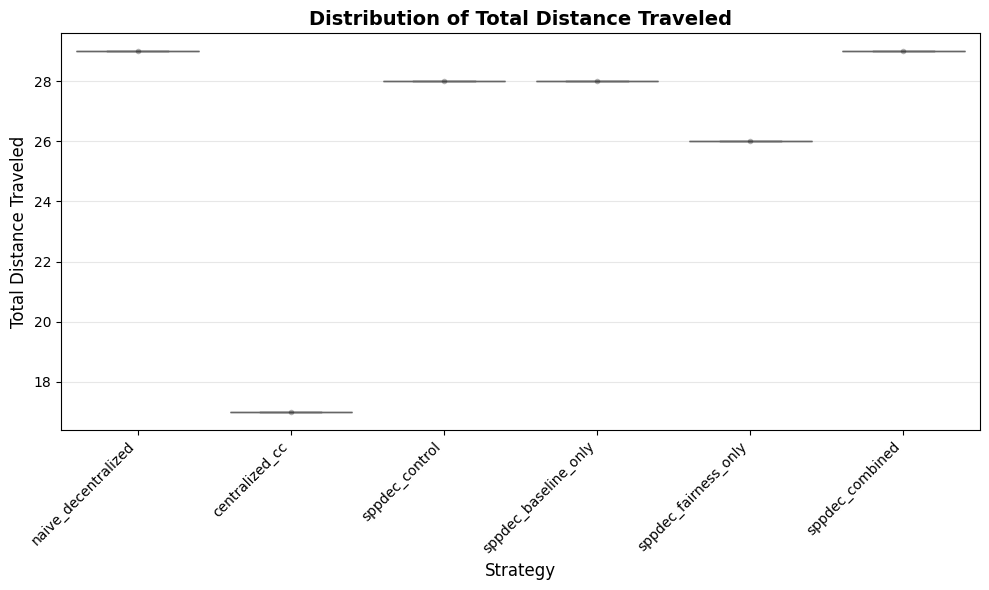

/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/aggregators.py:264: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/aggregators.py:289: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


✓ Saved boxplot: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report/boxplot_unsafe_failures.png


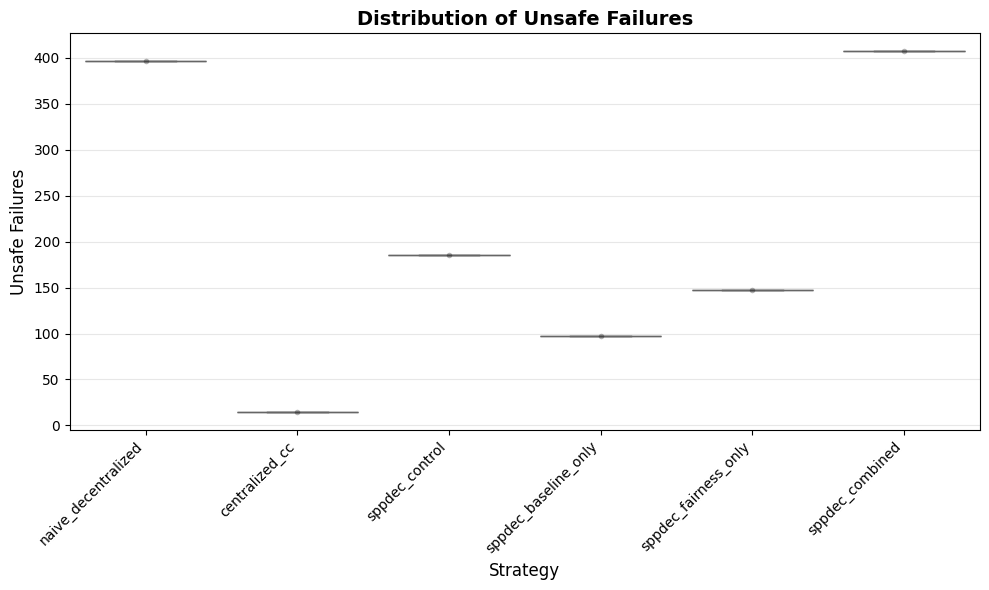


✓ Report generated in: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/report


In [8]:
analyzer.generate_report(REPORT_DIR)

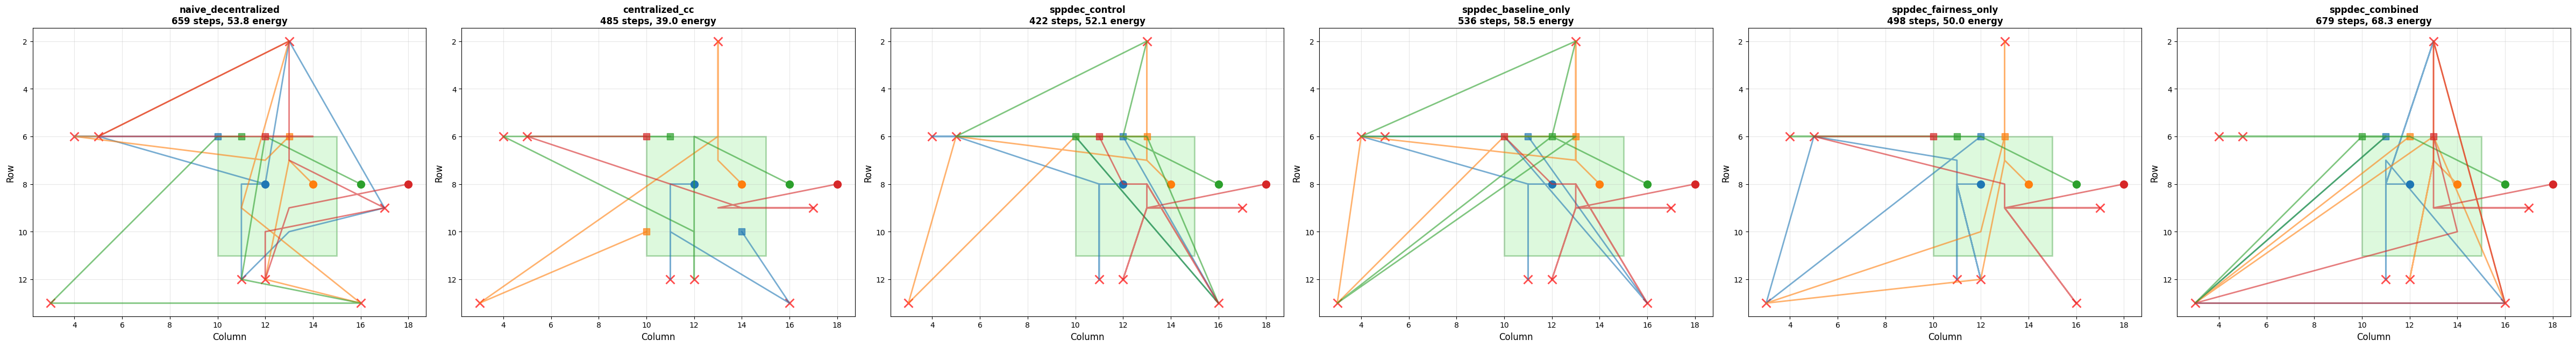

In [9]:
if experiments:
    exp = experiments[0]

    viz = TrajectoryVisualizer()
    viz.plot_comparison(
        experiment=exp,
        strategy_names=[s.strategy_name for s in exp.strategies]
    )

/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/visualizers.py:338: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


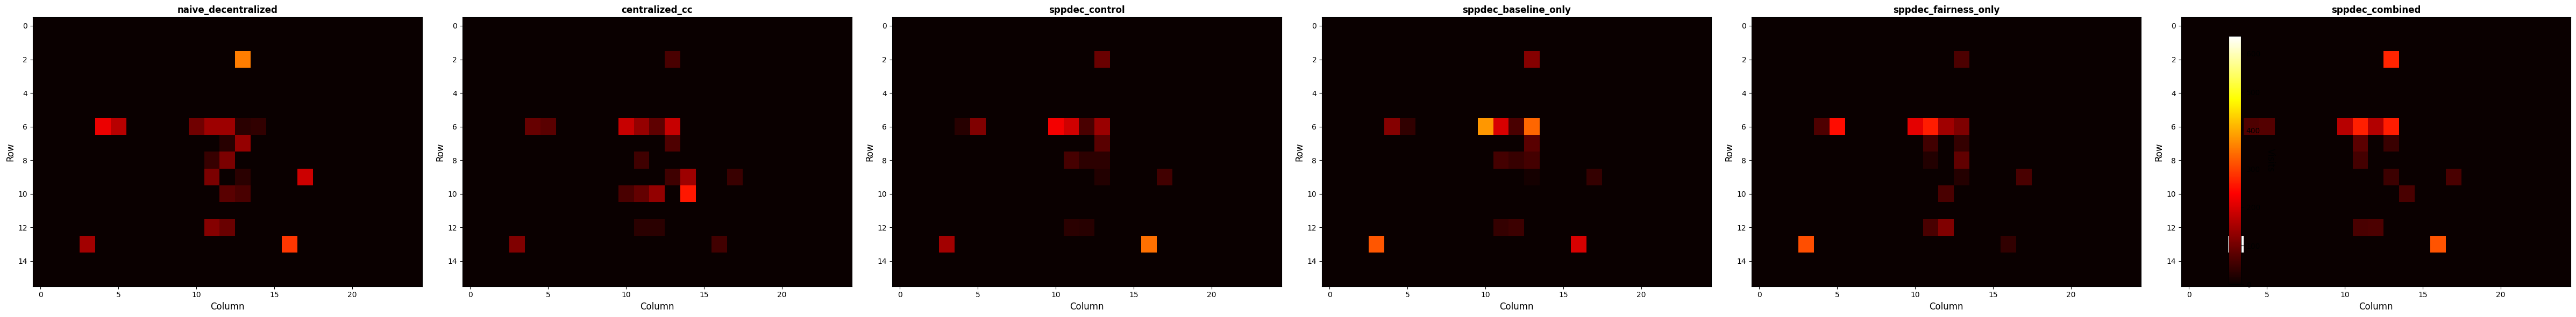

In [10]:
if experiments:
    heat = HeatmapVisualizer()

    heat.plot_comparison(
        experiment=exp,
        strategy_names=[s.strategy_name for s in exp.strategies]
    )

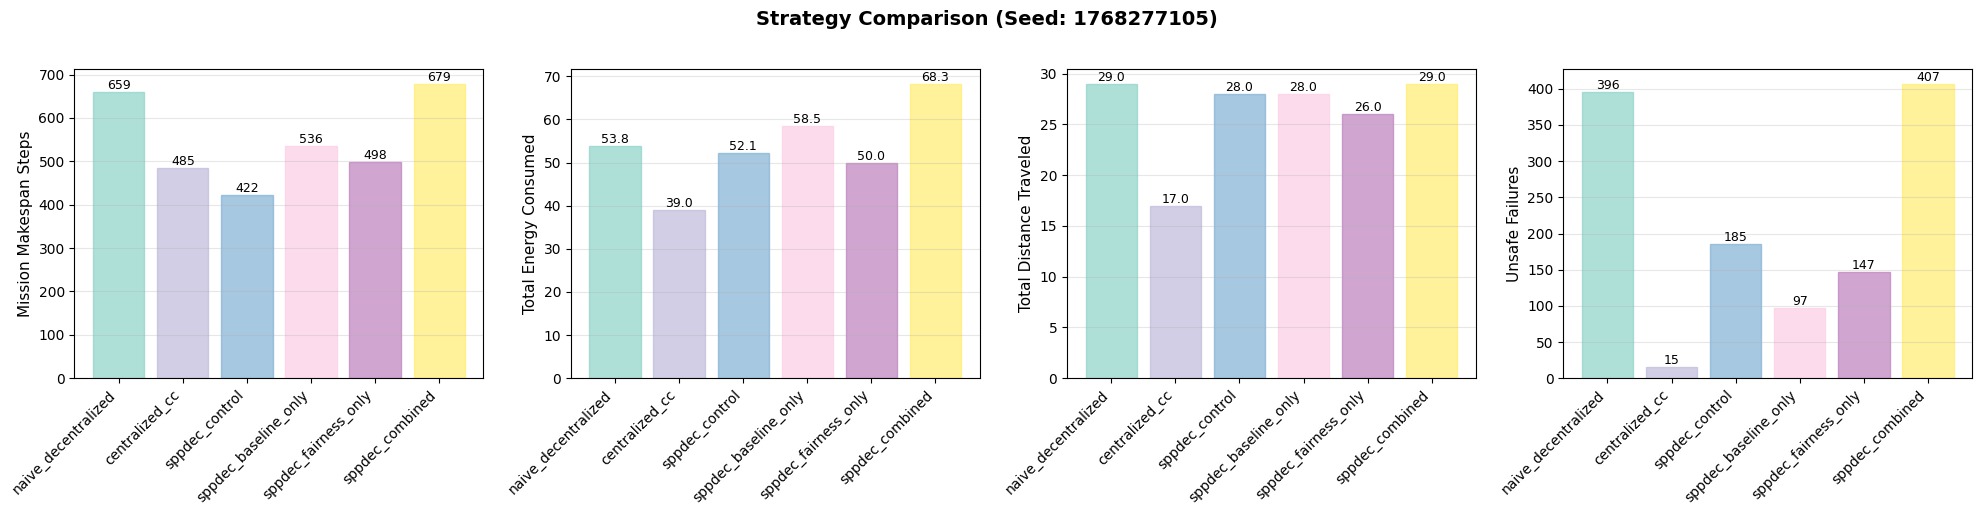

In [11]:
if experiments:
    metrics_viz = MetricsVisualizer()
    metrics_viz.plot_comparison(exp)